# General Overview of making OPENMC models of Nuclear Reactors

## Used for Cardinal Multiphysics simulation

### Goal

Build a Basic Understanding of how to use the OPENMC Python API. This tutorial uses the example of creating a basic Mono-block HTGR core.

**Note:** This tutorial assumes you understand the OpenMC architecture, and have OpenMC built through Cardinal.<br> If you have it built another way, you will need to modify the code in the setup section. <br>If you don't have it built, you can still look at the pre-provided outputs, but you will not be able to run any of the code sections

### Learning Objectives

&nbsp;1. Understand how to setup OPENMC Python API

&nbsp;2. Learn how to define OPENMC materials and properties in python

&nbsp;3. Learn how to define OPENMC geometries in python

&nbsp;4. Learn how to export those files into formats usable by further tools

# Setup

## Packages
We need to ensure any needed packages are all set for python. First, run the following code section, you can ignore anything about a version error

Expect output in this format:

word soup

0.16.1.dev14+g150f9ac04

<module 'openmc.lib' from '/home/jmiller/NEP/SSTA-NEP/.venv/lib/python3.14/site-packages/openmc/lib/__init__.py'>


In [59]:
t=False
if t:

    !python -m pip install pip-review
    !pip-review --auto
    !python -m pip install -r requirements.txt
    import openmc
    import openmc.lib
    print(openmc.__version__)
    print(openmc.lib)


If that code block runs without errors, you can keep going. If it does not, execute the following code block. It will gather the OpenMC Python Module

*Note: Whenever OpenMC is updated by cardinal in the future, it will require rebuilding the module, which you can do the short way with this code cell*

In [60]:

%%bash
if [ "$(python3 -c 'print(t)')" = "True" ]; then
    cd ${NEKRS_HOME%/*}/contrib/openmc
    git fetch --tags
    python -m pip install setuptools
    python -m pip install numpy
    python -m pip install .
    python -c "import openmc; import openmc.lib; print(openmc.__version__); print(openmc.lib)"
fi


Traceback (most recent call last):
  File "<string>", line 1, in <module>
    print(t)
          ^
NameError: name 't' is not defined


You should expect this output style from the above:

word soup

0.16.1.dev14+g150f9ac04

<module 'openmc.lib' from '/home/jmiller/NEP/SSTA-NEP/.venv/lib/python3.14/site-packages/openmc/lib/__init__.py'>

# Functions
Any neccessary imports and other setup.

In [61]:
import openmc
import openmc.stats
import openmc.model
import numpy as np
import os

# OpenMC Basic Tenants
Info to understand the structure of what we are about to do

## &nbsp;A. Structure


&nbsp;What goes into an OpenMC neutronics model?

### &nbsp;&nbsp;1. Geometry

&nbsp;&nbsp;&nbsp;Pretty Self-explanatory. Basically the actual structure of everything. OpenMC uses **CSG Models**, which is just a different way to go about things that a mesh. Basically, in CSG, to &nbsp;&nbsp;&nbsp;store a cube with a hole in it, it would be stored as a cube minus a cylinder, whereas a mesh is just the set of points that make up that cube with a hole in it

### &nbsp;&nbsp;2. Initial Conditions

&nbsp;&nbsp;&nbsp;Another Very straight forward component. Things like intial temperature, Values of any intial neutron sources being emitted into the problem.

### &nbsp;&nbsp;3. Materials

&nbsp;&nbsp;&nbsp;This is where the magic really happens. Materials are what OpenMC uses to store any and all material properties of the model. They are assigned to a given geometry, as we will see &nbsp;&nbsp;&nbsp;later. They store anything from density, to cross sections, to crystal structure.

## &nbsp;B. Layout


&nbsp;&nbsp;How are OpenMC model definitions laid out in the Python API?

### &nbsp;&nbsp;1. Define Materials

&nbsp;&nbsp;&nbsp;Any needed materials should be defined first, with all needed properties assigned.

### &nbsp;&nbsp;2. Outline the Model

&nbsp;&nbsp;&nbsp;Now setup the boundaries of the geometry with simple shapes. 

&nbsp;&nbsp;&nbsp;As an example, let's consider a mono-block reactor core from a very simple angle:<br><br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;1. The containment is a giant cylinder, so lets put a large cylinder parallel to the z-axis (called a zcylinder in openmc). Also, make another one but slightly bigger<br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;2. There are coolant channels running through the fuel, so let's define several more zcylinders across the inside of the containment cylinder<br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;3. We also need a lower and upper bound, lets define two circles at the top and bottom of the containment<br>


### &nbsp;&nbsp;3. Fill in the Model

&nbsp;&nbsp;&nbsp;Now we can fill in between boundaries with our materials<br>
&nbsp;&nbsp;&nbsp;Following that previous example, let's continue with it. For this part, it may seem confusing now, but it will make sense later<br><br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;1. Fill between the inside of containment boundary, the outside of the coolant channel bounds, and the top and bottom circles with fuel<br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;2. Fill inside coolant channel with coolant<br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;3. Fill between the outside of the containment inner bound, and the inside of the larger containment bound<br>

### &nbsp;&nbsp;&nbsp;4. Setup Model to Run

&nbsp;&nbsp;&nbsp;Now we need to begin setting the model parameters<br>
&nbsp;&nbsp;&nbsp;This looks like: initial conditions, what kind of simulation, how many particles, How to split up the simulation, etc.

# 1. Making OpenMC materials

## A. Create material
Define a material without properties

In [62]:
# Make our 4 materials we will use: fuel, coolant, reflector, cladding
uo2=openmc.Material(name="UO2 10% enriched")
he=openmc.Material(name="He")
beo=openmc.Material(name="BeO")
sic=openmc.Material(name="SiC")
ne=openmc.Material(name='Ne')

## B. Add Properties
Add properties like density, isotope 

In [63]:
# Add densities to all materials, for ease of use, we are using STP here
uo2.set_density('g/cm3',10.9600)
he.set_density('g/cm3',0.000166)
beo.set_density('g/cm3',3.010)
sic.set_density('g/cm3',3.210)
ne.set_density('g/cm3',0.00125)

# Add Isotope Quantities
uo2.add_element('U',1.,enrichment=10)
uo2.add_element('O',2.)

he.add_element('He',1.)

beo.add_element('Be',1.)
beo.add_element('O',1.)

sic.add_element('Si',1.)
sic.add_element('C',1.)

ne.add_element('Ne',1.)


/home/jmiller/NEP/SSTA-NEP/.venv/lib/python3.14/site-packages/openmc/material.py:1059: UserWarning: A uranium enrichment of 10 was given for Material ID="21". OpenMC assumes the U234/U235 mass ratio is constant at 0.008, which is only valid at low enrichments. Consider setting the isotopic composition manually for enrichments over 5%.
  warnings.warn(msg)


## C. Gather Materials together
Now we need to create a combined list for later

In [64]:
materials = openmc.Materials([uo2,he,beo,sic,ne])
materials.export_to_xml()

# 2. Creating OpenMC Geometry

## A. Create base shapes
We need to make general geometry for our mono-block

In [65]:
# Geometry constants
# All should be in cm
outerr=1500
reflectthick=200
coolantcount=6
coolantd=100
cladd=40
coolantr=800
height=20000
Stepcountsh=10


# Create Fuel and Reflector Z cyls
fuelbound=openmc.ZCylinder(0,0,outerr-reflectthick)
reflectbound=openmc.ZCylinder(0,0,outerr)

#Now to make the bounding box of nitrogen around core
upperr=[outerr,outerr,height]
lowerl=[-outerr,-outerr,0]

box=openmc.model.RectangularParallelepiped(
    xmin=-outerr,
    ymin=-outerr,
    xmax=outerr,
    ymax=outerr,
    zmin=0,
    zmax=height,
    boundary_type='reflective'
)
gap=-box & +reflectbound

#Create coolant channels
coolantpos=[coolantr,0,0]
theta=360/coolantcount

#Create rotated centers
coolantposl=[]
for i in range(0,coolantcount):  
    rmat=openmc.get_rotation_matrix((0,0,theta*i))
    coolantposl.append(np.matmul(rmat,coolantpos))
#Now make zcylinders there
coolantsl=[]
cladsl=[]
for i in range(0,coolantcount):
    coolantsl.append(openmc.ZCylinder(coolantposl[i][0],coolantposl[i][1],coolantd/2))
    cladsl.append(openmc.ZCylinder(coolantposl[i][0],coolantposl[i][1],(coolantd+cladd)/2))
#Now create fuel
fuel=-fuelbound
for i in range(0,coolantcount):
    fuel=fuel & +cladsl[i]
#Create Coolant, ref & cladding
coolant=-coolantsl[0]
clad=-cladsl[0]&+coolantsl[0]
for i in range(1,coolantcount):
    coolant=coolant | -coolantsl[i]
    clad=clad | (-cladsl[i]&+coolantsl[i])
reflect=-reflectbound & +fuelbound










## B. Create Layers
We need to then create "cells" or layered chunks of each

In [66]:
# Create planes to set the border between each vertical cell
heights=np.linspace(0,height,num=Stepcountsh+1)
steps=[]
for i in range(0,Stepcountsh+1):
    steps.append(openmc.ZPlane(heights[i]))
steps[0].boundary_type = 'vacuum'
steps[-1].boundary_type = 'vacuum'
#Now create the layer regions
layer=[]
for i in range(0,Stepcountsh):
    layer.append(+steps[i] & -steps[i+1])



## C. Create Cells
Using the materials we created, and the layered regions, create all the needed cells

In [67]:
#Create cell containers
gap_cells=[]
fuel_cells=[]
reflect_cells=[]
coolant_cells=[]
clad_cells=[]
all_cells=[]
for i in range(0,Stepcountsh):
    fuel_cells.append(openmc.Cell(fill=uo2, region=fuel & layer[i], name='Fuel{:n}'.format(i)))
    reflect_cells.append(openmc.Cell(fill=beo, region=reflect & layer[i], name='Reflector{:n}'.format(i)))
    clad_cells.append(openmc.Cell(fill=sic, region=clad & layer[i], name='Clad{:n}'.format(i)))
    coolant_cells.append(openmc.Cell(fill=he, region=coolant & layer[i], name='Coolant{:n}'.format(i)))
    gap_cells.append(openmc.Cell(fill=ne, region=gap & layer[i], name='Barrier{:n}'.format(i)))
    all_cells.append(fuel_cells[i])
    all_cells.append(reflect_cells[i])
    all_cells.append(clad_cells[i])
    all_cells.append(coolant_cells[i])
    all_cells.append(gap_cells[i])

## D. Export Geometry
Now get that geometry in xml for use by cardinal or OpenMC

In [68]:
geo=openmc.Geometry(all_cells)
geo.export_to_xml()

## E. Make Some Nice Pictures
It looks pretty, also good to understand what we have made

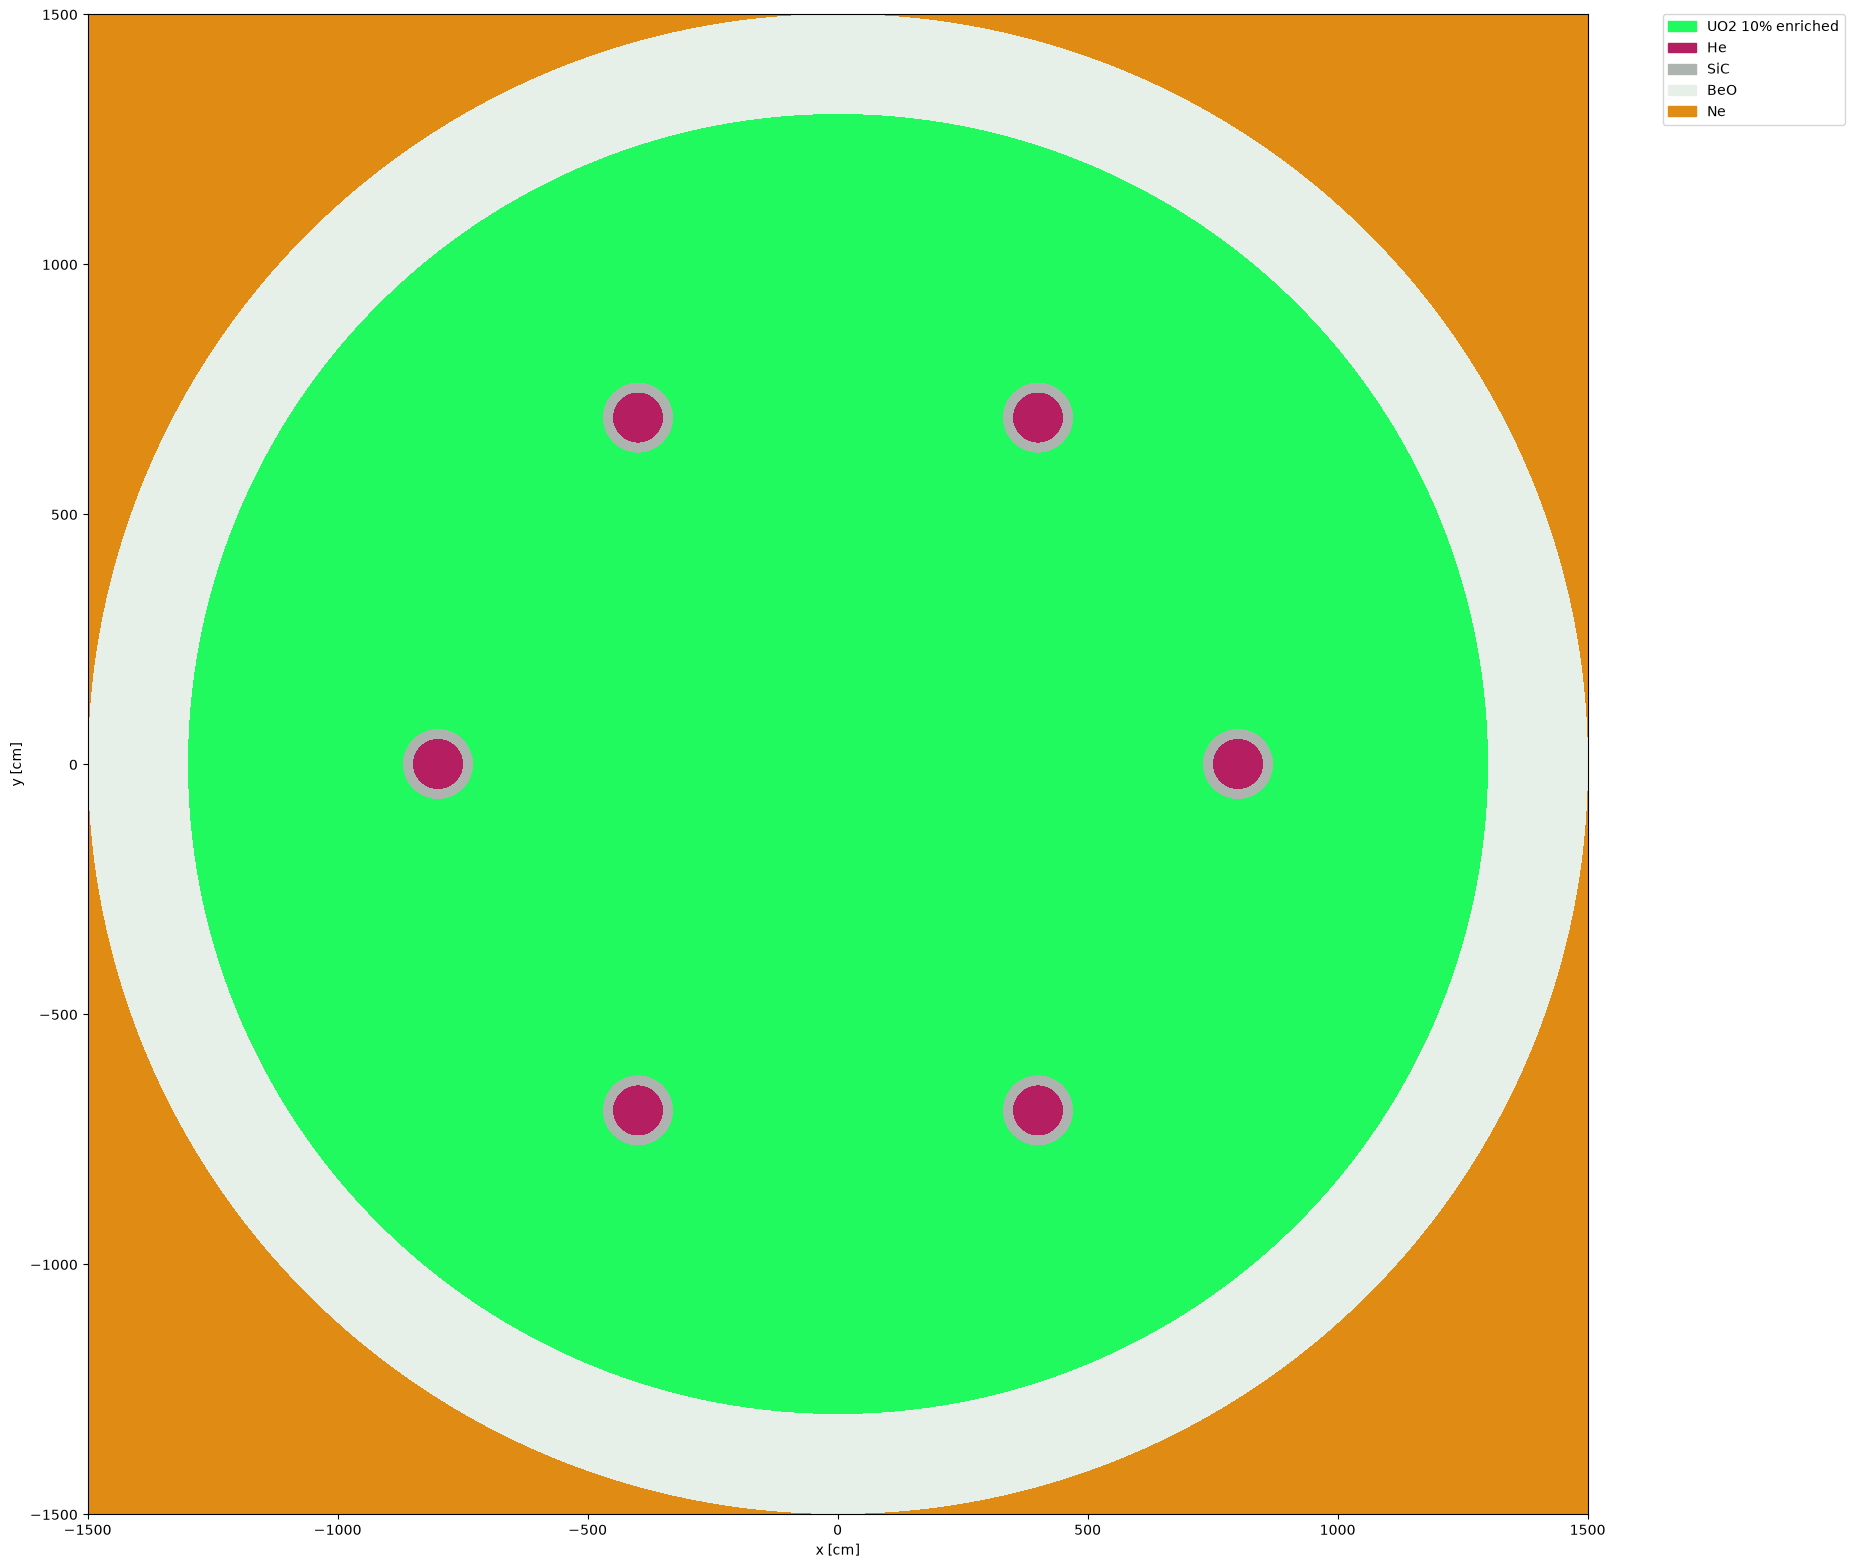

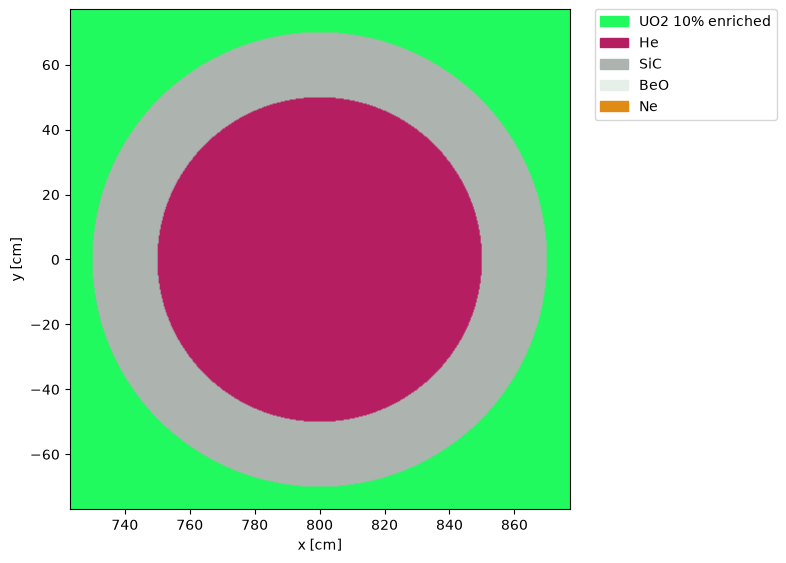

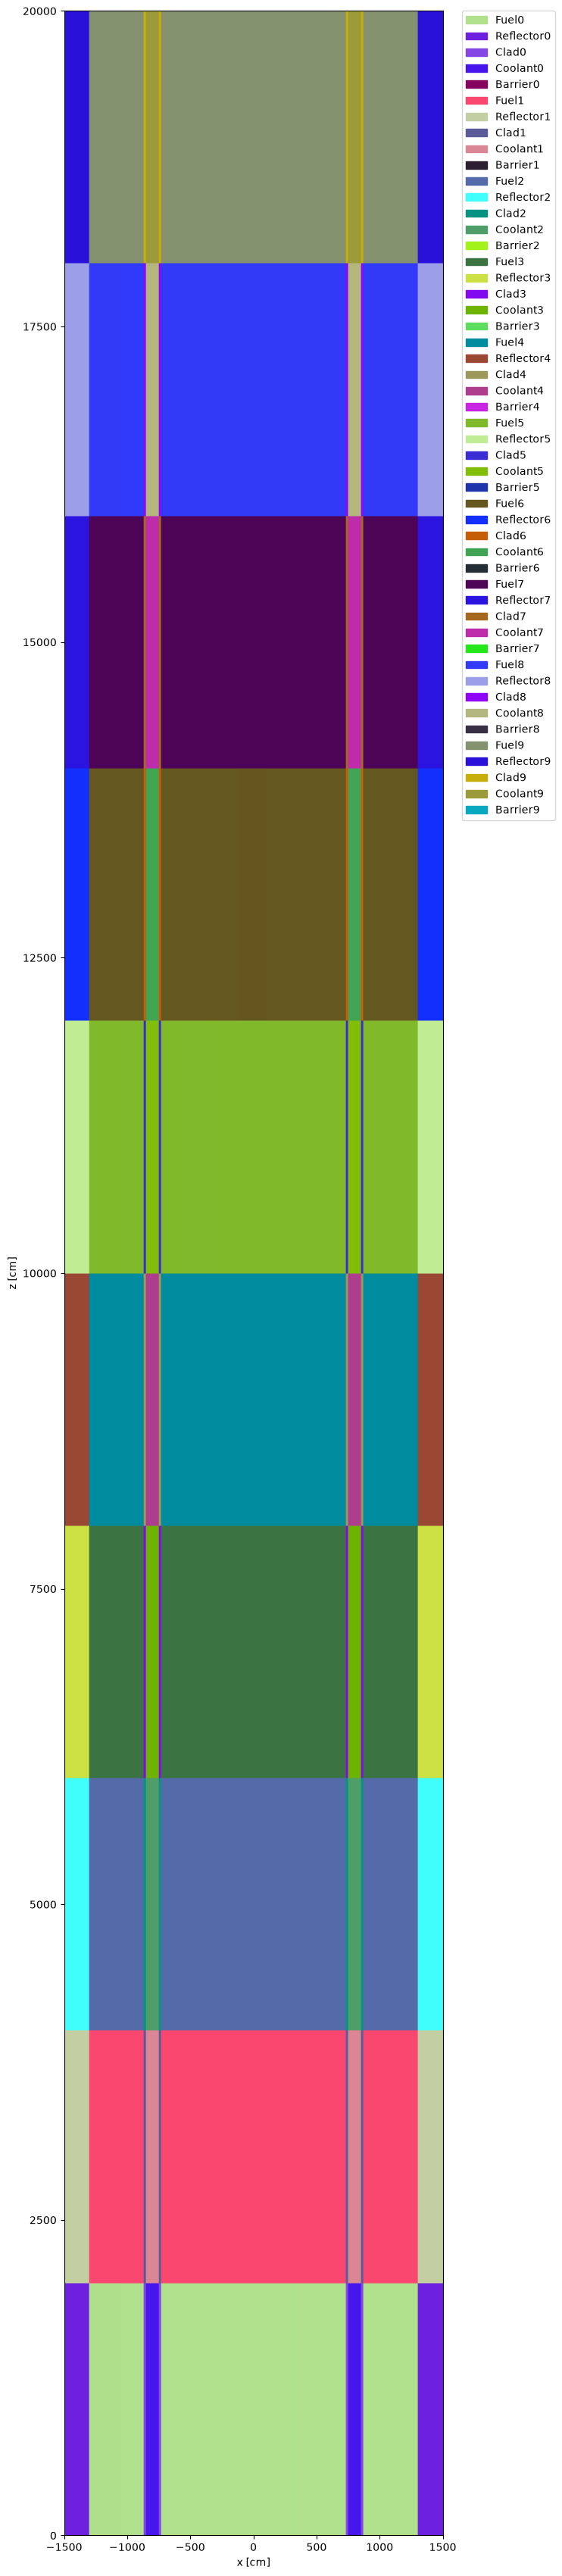

In [69]:
# create some plots to look at the geometry for the sake of the tutorial

#overall topdown view
plot1 = geo.plot(
    basis='xy',
    colors={uo2: (32, 250, 94), he: (181, 31, 98), sic: (173, 179, 174), beo: (230, 240, 232),ne: (224, 139, 20)},
    color_by='material',
    legend=True,
    width=[outerr*2,outerr*2],
    pixels=[1500,1500]
)
#Zoomed in on a coolant channel
plot2 = geo.plot(
    basis='xy',
    colors={uo2: (32, 250, 94), he: (181, 31, 98), sic: (173, 179, 174), beo: (230, 240, 232),ne: (224, 139, 20)},
    color_by='material',
    legend=True,
    origin=[coolantposl[0][0],coolantposl[0][1],height/2.0],
    width=[(coolantd+cladd)*1.1,(coolantd+cladd)*1.1],
    pixels=[500,500]
)
# Side on view

plot3 = geo.plot(
    basis='xz',
    color_by='cell',
    seed=50,
    legend=True,
    origin=[0,0,height/2],
    width=[(outerr)*2.0,height],
    pixels=[500,int(500*(height/(2*outerr)))]
)


# 3. Creating OpenMC Problem Settings

Create all the settings to actually run this problem on HPC or local machine

In [70]:
settings=openmc.Settings()
settings.particles=10000
settings.batches=1500
settings.inactive=250

uniform_dist = openmc.stats.Box(lowerl, upperr)
settings.source = openmc.IndependentSource(space=uniform_dist,constraints={'fissionable': True})

settings.temperature = {'default': 280.0 + 273.15,
                        'method': 'interpolation',
                        'range': (250.0, 3000.0),
                        'tolerance': 1000.0}

settings.export_to_xml()

#Something else, here, dw abt it

all_cells = list(geo.get_all_cells().values())
cell_ids = [cell.id for cell in all_cells]

cell_filter2 = openmc.CellFilter(cell_ids)

tallyf = openmc.Tally(name="Cell_flux")
tallyf.filters = [cell_filter2]
tallyf.scores = ["flux"]

cell_filter = openmc.CellFilter(fuel_cells)
tally = openmc.Tally(name="Cell_power_heat")
tally.filters = [cell_filter]
tally.scores = ["kappa-fission","heating"]



tallies = openmc.Tallies([tally,tallyf])


# 4. Create combined model file for later use

There are certain applications involving DAGMC where we need the whole package in one file, called model.xml

In [71]:
mod=openmc.Model(geometry=geo,materials=materials,settings=settings,tallies=tallies)
mod.export_to_model_xml()

# 5. Running an OpenMC model stand-alone

How do we actually run this with openmc, which surprise, surprise, we can run from Python!!!

In [72]:
openmc.run(geometry_debug=True,path_input="model.xml",threads=12)

                                %%%%%%%%%%%%%%%
                           %%%%%%%%%%%%%%%%%%%%%%%%
                        %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                      %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                    %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                   %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                                    %%%%%%%%%%%%%%%%%%%%%%%%
                                     %%%%%%%%%%%%%%%%%%%%%%%%
                 ###############      %%%%%%%%%%%%%%%%%%%%%%%%
                ##################     %%%%%%%%%%%%%%%%%%%%%%%
                ###################     %%%%%%%%%%%%%%%%%%%%%%%
                ####################     %%%%%%%%%%%%%%%%%%%%%%
                #####################     %%%%%%%%%%%%%%%%%%%%%
                ######################     %%%%%%%%%%%%%%%%%%%%
                #######################     %%%%%%%%%%%%%%%%%%
                 #######################     %%%%%%%%%%%%%%%%%
                 #####################

# 6. Interacting with OpenMC Results

We ran a sim, now what?

In [ ]:
import math
sp = openmc.StatePoint('statepoint.1500.h5')
print(f"Final k-eff: {sp.keff.nominal_value:.5f} +/- {sp.keff.std_dev:.5f}") # type: ignore
k_per_gen = sp.k_generation
print("k-eff for each generation:", np.array2string(k_per_gen, precision=5, floatmode='fixed')) # type: ignore
tally_ph=sp.get_tally(name="Cell_power_heat")
tally_f=sp.get_tally(name="Cell_flux")

p_res=tally_ph.get_values(scores=["kappa-fission"])
h_res=tally_ph.get_values(scores=["heating"])
f_res=tally_f.get_values(scores=["flux"])

print("Number of filter bins:", tally_ph.num_bins)
print("Filters:", tally_ph.filters)

p_avg=p_res.mean(axis=0).flatten()
f_avg=f_res.mean(axis=0).flatten()
h_avg=h_res.mean(axis=0).flatten()

joules_per_src = p_avg * 1.602176634e-19  # [J / source]
joules_per_src2 = h_avg * 1.602176634e-19  # [J / source]
source_rate = 1.0 # See OpenMC doc for why this is one

total_power = joules_per_src * source_rate 
total_heat = joules_per_src2 * source_rate 

vol=(((math.pi)*float(outerr))**2.0)*height

flux_per_src = h_avg/vol 

avg_flux=flux_per_src * source_rate

print(f"The found value for total power was",np.array2string(total_power, precision=5, floatmode='fixed'),"Watts per neutron!")

print(f"The found value for total heating was",np.array2string(total_heat, precision=5, floatmode='fixed'),"Watts per neutron!")

print(f"The found value for total flux was", np.array2string(avg_flux, precision=5, floatmode='fixed'),"Neutron/cm^2*s but like per neutron, it's weird, don't question the unit!")




Final k-eff: 1.16707 +/- 0.00021
k-eff for each generation: [1.13755 1.13928 1.13581 ... 1.15448 1.15423 1.16760]
Number of filter bins: 20
Filters: [CellFilter
	Bins           =	[201 206 211 216 221 226 231 236 241 246]
	ID             =	10
]
The found value for total power was [1.45154e-12] Watts per neutron!
The found value for total heating was [1.32451e-12] Watts per neutron!
The found value for total flux was [1.86137e-05] Neutron/cm^2*s but like per neutron, it's weird, don't question the unit!
